<a href="https://colab.research.google.com/github/zbnerd/ROKEY_prac/blob/main/261106_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 데이터 - AI hub 재활용품 분류 및 선별 데이터
## 링크
https://www.aihub.or.kr/aihubdata/data/view.do?currMenu=115&topMenu=100&searchKeyword=%EC%9E%AC%ED%99%9C%EC%9A%A9&aihubDataSe=data&dataSetSn=71362
## 검출대상 - 갈색 유리병

# 환경 설정 · 데이터 경로 · 모델 로드

In [1]:

%pip -q install ultralytics

from pathlib import Path
from itertools import product
from collections import Counter
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm
from ultralytics import YOLO
from google.colab import drive
from google.colab.patches import cv2_imshow
from IPython.display import display

# Google Drive 연결
drive.mount("/content/drive")

# 데이터 경로
BASE = Path("/content/drive/MyDrive/Colab Notebooks/AI개론/261106스터디")

SAMPLE_IMAGE_DIR = BASE / "sample_image"
SAMPLE_LABEL_DIR = BASE / "sample_label"
VAL_IMAGE_DIR = BASE / "validation_image"
VAL_LABEL_DIR = BASE / "validation_label"

for folder in [SAMPLE_IMAGE_DIR, SAMPLE_LABEL_DIR, VAL_IMAGE_DIR, VAL_LABEL_DIR]:
    assert folder.is_dir(), f"폴더가 없습니다: {folder}"

sample_images = sorted(SAMPLE_IMAGE_DIR.glob("*.jpg"))
val_images = sorted(VAL_IMAGE_DIR.glob("*.jpg"))

# 샘플에서 튜닝한 이미지는 별도 검증에서 제외
sample_names = {p.name for p in sample_images}
eval_images = [p for p in val_images if p.name not in sample_names]

# 공통 실험 설정
IOU_THRESHOLD = 0.5

OPENCV_CONFIG = {
    "low": 50,
    "high": 150,
    "kernel_size": (15, 5),
    "min_area": 32000,
    "min_side": 20,
    "max_ratio": 5.0,
    "use_clahe": False,
}

YOLO_CONFIG = {
    "conf": 0.03,
    "imgsz": 640,
}

MODEL_NAME = "yolo26n.pt"
DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"

model = YOLO(MODEL_NAME)
bottle_id = next(
    (int(i) for i, name in model.names.items()
     if name.lower() == "bottle"),
    None
)
assert bottle_id is not None, "bottle 클래스를 찾지 못했습니다."

print(f"Sample: {len(sample_images)}장")
print(f"Validation: {len(val_images)}장")
print(f"Validation 평가 대상: {len(eval_images)}장")
print(f"Model: {MODEL_NAME} / Device: {DEVICE}")
print(f"Bottle class ID: {bottle_id}")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Mounted at /content/drive
Sample: 10장
Validation: 895장
Validation 평가 대상: 895장
Model: yolo26n.pt / Device: cuda:0
Bottle class ID: 39


# 데이터 로딩 · GT 보정 · IoU 평가

download.svg

- IoU = (교집합면적) / (합집합면적)
- 예를들어 IoU가 0.7이면 두 박스의 겹치는 면적이 합치는 면적의 70%

- IoU: 검출한 위치가 정답과 얼마나 일치하는가?
- Precision: 검출했다고 판단한 것 중 실제 정답은 얼마나 되는가?
- Recall: 실제 존재하는 병 중 얼마나 찾아냈는가?
- F1 Score: Precision과 Recall의 균형은 어떠한가?

In [2]:

def load_sample(image_path, label_dir):
    image_path = Path(image_path)
    label_path = Path(label_dir) / f"{image_path.stem}.json"

    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(image_path)

    with open(label_path, encoding="utf-8-sig") as f:
        data = json.load(f)

    expected = data["IMAGE_INFO"]["FILE_NAME"]
    if expected != image_path.name:
        raise ValueError(f"이미지/라벨 불일치: {image_path.name} != {expected}")

    img_h, img_w = image.shape[:2]
    gt_boxes = []

    for obj in data.get("ANNOTATION_INFO", []):
        # 현재 목표: 갈색 유리병
        if obj.get("CLASS") != "유리병":
            continue
        if obj.get("DETAILS") != "갈색":
            continue

        shape = obj.get("SHAPE_TYPE")
        points = obj.get("POINTS")

        if not points:
            continue

        if shape == "BOX":
            x, y, w, h = map(float, points[0])
            x1, y1, x2, y2 = x, y, x + w, y + h

        elif shape == "POLYGON":
            pts = np.asarray(points, dtype=np.float64)
            if pts.ndim == 3 and pts.shape[0] == 1:
                pts = pts[0]
            if pts.ndim != 2 or pts.shape[1] != 2:
                raise ValueError(f"잘못된 POLYGON: {label_path}")

            x1, y1 = pts.min(axis=0)
            x2, y2 = pts.max(axis=0)

        else:
            continue

        x1, x2 = np.clip([x1, x2], 0, img_w)
        y1, y2 = np.clip([y1, y2], 0, img_h)

        if x2 > x1 and y2 > y1:
            gt_boxes.append((
                float(x1), float(y1),
                float(x2 - x1), float(y2 - y1)
            ))

    return image, gt_boxes


def calculate_iou(a, b):
    x1, y1, w1, h1 = a
    x2, y2, w2, h2 = b

    iw = max(0, min(x1 + w1, x2 + w2) - max(x1, x2))
    ih = max(0, min(y1 + h1, y2 + h2) - max(y1, y2))

    intersection = iw * ih
    union = w1 * h1 + w2 * h2 - intersection

    return intersection / union if union > 0 else 0.0


def calculate_metrics(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0

    return {
        "TP": tp, "FP": fp, "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


def evaluate_detections(gt_boxes, candidates, threshold=IOU_THRESHOLD):
    pairs = []

    for gi, gt in enumerate(gt_boxes):
        for ci, candidate in enumerate(candidates):
            iou = calculate_iou(gt, candidate)
            if iou >= threshold:
                pairs.append((iou, gi, ci))

    # IoU가 높은 쌍부터 Greedy 1:1 매칭
    pairs.sort(reverse=True)

    matched_gt = set()
    matched_candidates = set()
    matches = []

    for iou, gi, ci in pairs:
        if gi in matched_gt or ci in matched_candidates:
            continue

        matched_gt.add(gi)
        matched_candidates.add(ci)
        matches.append((gi, ci, iou))

    tp = len(matches)
    fp = len(candidates) - tp
    fn = len(gt_boxes) - tp

    return calculate_metrics(tp, fp, fn), matches


def summary_table(df):
    """이미지별 결과를 Method별 Micro Precision/Recall/F1으로 집계."""
    rows = []

    for method, group in df.groupby("Method", sort=False):
        totals = group[["GT", "Candidates", "TP", "FP", "FN"]].sum()
        m = calculate_metrics(
            int(totals["TP"]),
            int(totals["FP"]),
            int(totals["FN"])
        )

        rows.append({
            "Method": method,
            "Images": len(group),
            "GT": int(totals["GT"]),
            "Candidates": int(totals["Candidates"]),
            "TP": m["TP"],
            "FP": m["FP"],
            "FN": m["FN"],
            "Precision (%)": m["Precision"] * 100,
            "Recall (%)": m["Recall"] * 100,
            "F1 (%)": m["F1"] * 100,
        })

    return pd.DataFrame(rows)


# POLYGON 보정 회귀 테스트 (기존 노트북의 검증 사례)
test_cases = {
    "1091356@0_07001_220919_P1_T3__2352.jpg": 9,
    "817394@0_07001_220822_P1_T3__0430.jpg": 2,
    "838670@0_07001_220822_P1_T3__2131.jpg": 6,
}

for filename, expected in test_cases.items():
    path = VAL_IMAGE_DIR / filename
    if path.exists():
        _, boxes = load_sample(path, VAL_LABEL_DIR)
        assert len(boxes) == expected, (filename, len(boxes), expected)

print("GT 로더 및 평가 함수 준비 완료")


GT 로더 및 평가 함수 준비 완료


# OpenCV · YOLO 검출 파이프라인

In [3]:

def detect_opencv(
    image, *,
    low=50, high=150,
    kernel_size=(15, 5),
    min_area=32000,
    min_side=20,
    max_ratio=5.0,
    use_clahe=False,
    return_steps=False
):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if use_clahe:
        gray = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(gray)

    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, low, high)

    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, kernel_size)
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    candidates = []

    for contour in contours:
        x, y, w, h = cv2.boundingRect(contour)

        if w * h < min_area or min(w, h) < min_side:
            continue

        ratio = max(w, h) / min(w, h)
        if max_ratio is not None and ratio > max_ratio:
            continue

        candidates.append((x, y, w, h))

    if return_steps:
        steps = {
            "Gray": gray,
            "Gaussian Blur": blurred,
            "Canny": edges,
            "Closing": closed
        }
        return candidates, steps

    return candidates


def detect_yolo(image, conf=0.03, imgsz=640):
    result = model.predict(
        source=image,
        classes=[bottle_id],
        conf=conf,
        imgsz=imgsz,
        device=DEVICE,
        verbose=False
    )[0]

    if result.boxes is None:
        return [], []

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()

    candidates = [
        (float(x1), float(y1), float(x2 - x1), float(y2 - y1))
        for x1, y1, x2, y2 in boxes
    ]

    return candidates, scores.tolist()


def evaluate_dataset(image_paths, label_dir, description="평가"):
    """두 검출기를 같은 이미지·GT·IoU 기준으로 평가."""
    records = []

    for path in tqdm(image_paths, desc=description):
        image, gt_boxes = load_sample(path, label_dir)

        opencv_boxes = detect_opencv(image, **OPENCV_CONFIG)
        yolo_boxes, _ = detect_yolo(image, **YOLO_CONFIG)

        for method, candidates in [
            ("OpenCV", opencv_boxes),
            ("YOLO26n", yolo_boxes)
        ]:
            metrics, _ = evaluate_detections(gt_boxes, candidates)

            records.append({
                "Image": path.name,
                "Method": method,
                "GT": len(gt_boxes),
                "Candidates": len(candidates),
                "TP": metrics["TP"],
                "FP": metrics["FP"],
                "FN": metrics["FN"]
            })

    return pd.DataFrame(records)


print("OpenCV / YOLO 검출 파이프라인 준비 완료")


OpenCV / YOLO 검출 파이프라인 준비 완료


# 샘플 10장으로 파라미터 튜닝

In [4]:

samples = [
    load_sample(path, SAMPLE_LABEL_DIR)
    for path in sample_images
]

# ── OpenCV 파라미터 탐색 ──
cv_trials = []

cv_configs = list(product(
    [False, True],                        # CLAHE
    [(3, 3), (7, 7), (15, 5)],           # Closing kernel
    [4000, 20000, 32000],                # 최소 면적
    [None, 5.0]                          # 최대 종횡비
))

for clahe, kernel, min_area, max_ratio in tqdm(
    cv_configs, desc="OpenCV 튜닝"
):
    records = []

    for image, gt_boxes in samples:
        candidates = detect_opencv(
            image,
            kernel_size=kernel,
            min_area=min_area,
            max_ratio=max_ratio,
            use_clahe=clahe
        )
        m, _ = evaluate_detections(gt_boxes, candidates)

        records.append({
            "Method": "OpenCV",
            "GT": len(gt_boxes),
            "Candidates": len(candidates),
            "TP": m["TP"], "FP": m["FP"], "FN": m["FN"]
        })

    score = summary_table(pd.DataFrame(records)).iloc[0]

    cv_trials.append({
        "CLAHE": clahe,
        "Kernel": str(kernel),
        "min_area": min_area,
        "max_ratio": max_ratio,
        **score[["Candidates", "TP", "FP", "FN",
                 "Precision (%)", "Recall (%)", "F1 (%)"]].to_dict()
    })

df_cv_tuning = pd.DataFrame(cv_trials)

print("===== OpenCV BEST CONFIGS =====")
display(
    df_cv_tuning.sort_values(
        ["F1 (%)", "TP", "FP"],
        ascending=[False, False, True]
    ).head(15).round(2)
)


# ── YOLO 파라미터 탐색 ──
yolo_trials = []
conf_values = [0.01, 0.03, 0.05, 0.10, 0.20, 0.30]

for imgsz in tqdm([640, 960, 1280], desc="YOLO 튜닝"):
    # 최저 Confidence로 한 번 추론한 뒤 결과 캐싱
    cached = [
        (gt, *detect_yolo(image, conf=0.01, imgsz=imgsz))
        for image, gt in samples
    ]

    for conf in conf_values:
        records = []

        for gt_boxes, boxes, scores in cached:
            candidates = [
                box for box, score in zip(boxes, scores)
                if score >= conf
            ]

            m, _ = evaluate_detections(gt_boxes, candidates)

            records.append({
                "Method": "YOLO26n",
                "GT": len(gt_boxes),
                "Candidates": len(candidates),
                "TP": m["TP"], "FP": m["FP"], "FN": m["FN"]
            })

        score = summary_table(pd.DataFrame(records)).iloc[0]

        yolo_trials.append({
            "Image Size": imgsz,
            "Confidence": conf,
            **score[["Candidates", "TP", "FP", "FN",
                     "Precision (%)", "Recall (%)", "F1 (%)"]].to_dict()
        })

df_yolo_tuning = pd.DataFrame(yolo_trials)

print("===== YOLO BEST CONFIGS =====")
display(
    df_yolo_tuning.sort_values(
        ["F1 (%)", "TP", "FP"],
        ascending=[False, False, True]
    ).head(15).round(2)
)


OpenCV 튜닝:   0%|          | 0/36 [00:00<?, ?it/s]

===== OpenCV BEST CONFIGS =====


,CLAHE,Kernel,min_area,max_ratio,Candidates,TP,FP,FN,Precision (%),Recall (%),F1 (%)
17,False,"(15, 5)",32000,5.0,52,7,45,23,13.46,23.33,17.07
16,False,"(15, 5)",32000,NaN,55,7,48,23,12.73,23.33,16.47
11,False,"(7, 7)",32000,5.0,50,6,44,24,12.00,20.00,15.00
10,False,"(7, 7)",32000,NaN,53,6,47,24,11.32,20.00,14.46
15,False,"(15, 5)",20000,5.0,83,8,75,22,9.64,26.67,14.16
14,False,"(15, 5)",20000,NaN,86,8,78,22,9.30,26.67,13.79
5,False,"(3, 3)",32000,5.0,31,4,27,26,12.90,13.33,13.11
4,False,"(3, 3)",32000,NaN,33,4,29,26,12.12,13.33,12.70
9,False,"(7, 7)",20000,5.0,84,7,77,23,8.33,23.33,12.28
8,False,"(7, 7)",20000,NaN,87,7,80,23,8.05,23.33,11.97


YOLO 튜닝:   0%|          | 0/3 [00:00<?, ?it/s]

===== YOLO BEST CONFIGS =====


,Image Size,Confidence,Candidates,TP,FP,FN,Precision (%),Recall (%),F1 (%)
1,640,0.03,21,9,12,21,42.86,30.00,35.29
8,960,0.05,22,8,14,22,36.36,26.67,30.77
2,640,0.05,12,6,6,24,50.00,20.00,28.57
0,640,0.01,42,10,32,20,23.81,33.33,27.78
7,960,0.03,35,9,26,21,25.71,30.00,27.69
9,960,0.10,10,5,5,25,50.00,16.67,25.00
6,960,0.01,83,14,69,16,16.87,46.67,24.78
14,1280,0.05,10,4,6,26,40.00,13.33,20.00
3,640,0.10,3,3,0,27,100.00,10.00,18.18
13,1280,0.03,20,4,16,26,20.00,13.33,16.00


# 샘플 비교 · 전처리 과정 시각화

Sample 평가:   0%|          | 0/10 [00:00<?, ?it/s]

===== SAMPLE PERFORMANCE =====


,Method,Images,GT,Candidates,TP,FP,FN,Precision (%),Recall (%),F1 (%)
0,OpenCV,10,30,52,7,45,23,13.46,23.33,17.07
1,YOLO26n,10,30,21,9,12,21,42.86,30.00,35.29


,Image,Method,GT,Candidates,TP,FP,FN
0,561203@0_07001_220822_P1_T3__0771.jpg,OpenCV,2,7,1,6,1
1,561203@0_07001_220822_P1_T3__0771.jpg,YOLO26n,2,2,0,2,2
2,561212@0_07001_220822_P1_T3__0372.jpg,OpenCV,4,7,1,6,3
3,561212@0_07001_220822_P1_T3__0372.jpg,YOLO26n,4,6,3,3,1
4,561218@0_07001_220822_P1_T3__0244.jpg,OpenCV,3,1,0,1,3
5,561218@0_07001_220822_P1_T3__0244.jpg,YOLO26n,3,1,1,0,2
6,561241@0_07001_220822_P1_T3__0590.jpg,OpenCV,3,6,1,5,2
7,561241@0_07001_220822_P1_T3__0590.jpg,YOLO26n,3,2,2,0,1
8,561289@0_07001_220822_P1_T3__0373.jpg,OpenCV,1,3,1,2,0
9,561289@0_07001_220822_P1_T3__0373.jpg,YOLO26n,1,0,0,0,1



Image: 561203@0_07001_220822_P1_T3__0771.jpg
GT: 2 | OpenCV: 7 | YOLO: 2
왼쪽: 원본 / 가운데: OpenCV / 오른쪽: YOLO


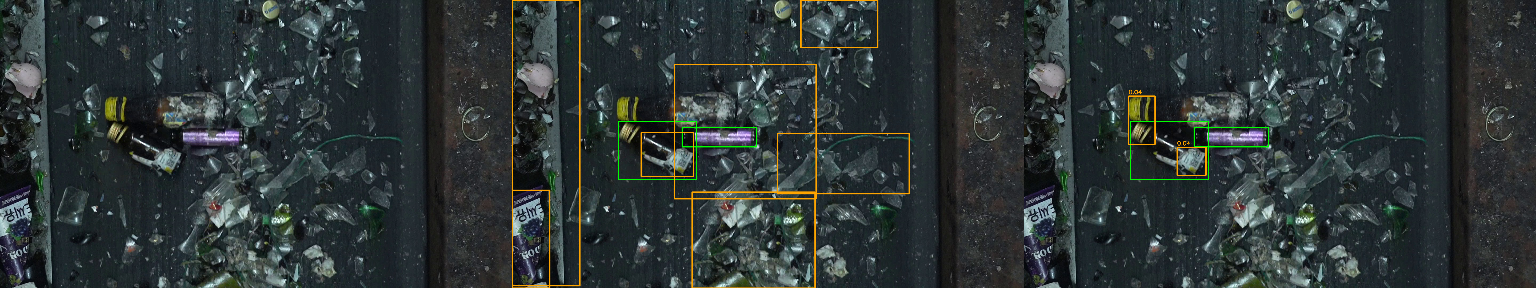

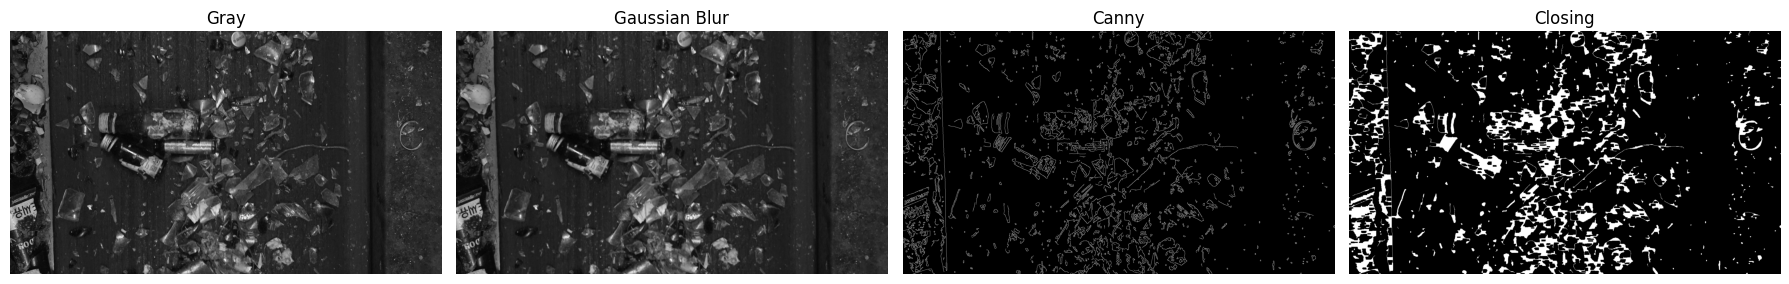

In [5]:

# 샘플 10장 성능 비교
df_sample = evaluate_dataset(
    sample_images, SAMPLE_LABEL_DIR, "Sample 평가"
)

print("===== SAMPLE PERFORMANCE =====")
display(summary_table(df_sample).round(2))
display(df_sample)


def visualize_comparison(image_path, label_dir):
    image, gt_boxes = load_sample(image_path, label_dir)

    cv_boxes, steps = detect_opencv(
        image, **OPENCV_CONFIG, return_steps=True
    )
    yolo_boxes, scores = detect_yolo(image, **YOLO_CONFIG)

    def draw_boxes(canvas, boxes, color, scores=None):
        for i, (x, y, w, h) in enumerate(boxes):
            p1 = (int(x), int(y))
            p2 = (int(x + w), int(y + h))
            cv2.rectangle(canvas, p1, p2, color, 3)

            if scores is not None:
                cv2.putText(
                    canvas, f"{scores[i]:.2f}",
                    (p1[0], max(20, p1[1] - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2
                )

    cv_view = image.copy()
    yolo_view = image.copy()

    # 초록: GT / 주황: 검출 후보
    for canvas in [cv_view, yolo_view]:
        draw_boxes(canvas, gt_boxes, (0, 255, 0))

    draw_boxes(cv_view, cv_boxes, (0, 165, 255))
    draw_boxes(yolo_view, yolo_boxes, (0, 165, 255), scores)

    print(f"\nImage: {Path(image_path).name}")
    print(f"GT: {len(gt_boxes)} | OpenCV: {len(cv_boxes)} | YOLO: {len(yolo_boxes)}")
    print("왼쪽: 원본 / 가운데: OpenCV / 오른쪽: YOLO")

    views = [
        cv2.resize(v, (512, 288))
        for v in [image, cv_view, yolo_view]
    ]
    cv2_imshow(np.hstack(views))

    return steps


# 첫 번째 이미지 비교
steps = visualize_comparison(
    sample_images[0], SAMPLE_LABEL_DIR
)

# OpenCV 전처리 과정 확인
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, (name, step_image) in zip(axes, steps.items()):
    ax.imshow(step_image, cmap="gray")
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()


# 전체 평가 및 CSV 저장

In [6]:
from tqdm.auto import tqdm

CSV_PATH = BASE / "validation_evaluation_corrected.csv"
REBUILD_VALIDATION = False

# 새로 평가하거나 기존 보정 결과 불러오기
if REBUILD_VALIDATION or not CSV_PATH.exists():
    df_val = evaluate_dataset(
        tqdm(
            eval_images,
            desc="Validation 평가",
            unit="image",
            dynamic_ncols=True
        ),
        VAL_LABEL_DIR,
        "Validation 평가"
    )

    df_val.to_csv(
        CSV_PATH, index=False, encoding="utf-8-sig"
    )
    print("새 평가 결과 저장:", CSV_PATH)

else:
    df_val = pd.read_csv(CSV_PATH)
    print("기존 평가 결과 사용:", CSV_PATH)


# 평가 데이터 무결성 확인
assert set(df_val["Method"]) == {"OpenCV", "YOLO26n"}
assert not df_val.duplicated(["Image", "Method"]).any()

cv_check = (
    df_val[df_val["Method"] == "OpenCV"]
    .set_index("Image").sort_index()
)
yolo_check = (
    df_val[df_val["Method"] == "YOLO26n"]
    .set_index("Image").sort_index()
)

assert cv_check.index.equals(yolo_check.index)
assert cv_check["GT"].equals(yolo_check["GT"])

# 검증 결과
print("\n===== VALIDATION PERFORMANCE =====")
display(summary_table(df_val).round(2))

print("\n평가 이미지 수:", df_val["Image"].nunique())
print("전체 GT:", cv_check["GT"].sum())


# JSON 라벨의 BOX / POLYGON 구성 확인
shape_counts = Counter()
polygon_only = mixed = zero_gt = 0

for path in tqdm(
    val_images,
    desc="GT 라벨 분석",
    unit="image",
    dynamic_ncols=True
):
    with open(
        VAL_LABEL_DIR / f"{path.stem}.json",
        encoding="utf-8-sig"
    ) as f:
        data = json.load(f)

    target_annotations = [
        a for a in data.get("ANNOTATION_INFO", [])
        if a.get("CLASS") == "유리병"
        and a.get("DETAILS") == "갈색"
    ]

    shapes = Counter(
        a.get("SHAPE_TYPE") for a in target_annotations
    )
    shape_counts.update(shapes)

    if shapes["POLYGON"] and not shapes["BOX"]:
        polygon_only += 1
    if shapes["POLYGON"] and shapes["BOX"]:
        mixed += 1
    if not shapes["POLYGON"] and not shapes["BOX"]:
        zero_gt += 1

print("\n===== GT LABEL ANALYSIS =====")
print("BOX:", shape_counts["BOX"])
print("POLYGON:", shape_counts["POLYGON"])
print("POLYGON-only images:", polygon_only)
print("Mixed images:", mixed)
print("No target annotation:", zero_gt)

기존 평가 결과 사용: /content/drive/MyDrive/Colab Notebooks/AI개론/261106스터디/validation_evaluation_corrected.csv

===== VALIDATION PERFORMANCE =====


,Method,Images,GT,Candidates,TP,FP,FN,Precision (%),Recall (%),F1 (%)
0,OpenCV,895,2268,4216,570,3646,1698,13.52,25.13,17.58
1,YOLO26n,895,2268,2757,856,1901,1412,31.05,37.74,34.07



평가 이미지 수: 895
전체 GT: 2268


GT 라벨 분석:   0%|          | 0/895 [00:00<?, ?image/s]


===== GT LABEL ANALYSIS =====
BOX: 1911
POLYGON: 357
POLYGON-only images: 143
Mixed images: 0
No target annotation: 0


# Oracle Hybrid · Fallback · 이미지별 승패 분석

In [7]:

# 모델별 결과 정렬
cv = (
    df_val[df_val["Method"] == "OpenCV"]
    .set_index("Image").sort_index()
)
yolo = (
    df_val[df_val["Method"] == "YOLO26n"]
    .set_index("Image").sort_index()
)

assert cv.index.equals(yolo.index)
assert cv["GT"].equals(yolo["GT"])


def image_f1(df):
    denominator = 2 * df["TP"] + df["FP"] + df["FN"]
    return (
        2 * df["TP"] / denominator.replace(0, np.nan)
    ).fillna(0.0)


cv_f1 = image_f1(cv)
yolo_f1 = image_f1(yolo)

analysis = pd.DataFrame({
    "OpenCV F1": cv_f1,
    "YOLO F1": yolo_f1,
    "OpenCV Candidates": cv["Candidates"],
    "YOLO Candidates": yolo["Candidates"]
})

analysis["Winner"] = np.select(
    [
        cv_f1 > yolo_f1 + 1e-12,
        yolo_f1 > cv_f1 + 1e-12
    ],
    ["OpenCV", "YOLO"],
    default="Tie"
)

print("===== 이미지별 승리 횟수 =====")
print(analysis["Winner"].value_counts())

print("\n===== 승리 모델별 후보 수 =====")
display(
    analysis.groupby("Winner")[
        ["OpenCV Candidates", "YOLO Candidates"]
    ].agg(["mean", "median"]).round(2)
)

print("\n===== OpenCV가 확실하게 이긴 이미지 =====")
display(
    analysis[analysis["Winner"] == "OpenCV"]
    .sort_values("OpenCV F1", ascending=False)
    .head(20).round(3)
)


# ── Oracle Hybrid ──
# GT를 알고 있을 때 이미지마다 더 높은 F1 모델 선택
# 동률이면 FP가 더 적은 모델 선택, 완전 동률은 YOLO
use_cv_oracle = (
    (cv_f1 > yolo_f1 + 1e-12)
    | (
        np.isclose(cv_f1, yolo_f1, rtol=0, atol=1e-12)
        & (cv["FP"] < yolo["FP"])
    )
)

columns = ["Candidates", "TP", "FP", "FN"]

oracle = yolo.copy()
oracle.loc[use_cv_oracle, columns] = cv.loc[use_cv_oracle, columns]
oracle["Method"] = "Oracle Hybrid"

analysis["Oracle Selected"] = np.where(
    use_cv_oracle, "OpenCV", "YOLO26n"
)


# ── Practical Fallback ──
# YOLO 후보가 없을 때만 OpenCV 결과 사용
use_cv_fallback = yolo["Candidates"] == 0

fallback = yolo.copy()
fallback.loc[use_cv_fallback, columns] = cv.loc[
    use_cv_fallback, columns
]
fallback["Method"] = "YOLO → OpenCV Fallback"


# ── 전체 성능 비교 ──
all_results = pd.concat([
    cv.reset_index(),
    yolo.reset_index(),
    oracle.reset_index(),
    fallback.reset_index()
], ignore_index=True)

print("\n===== FINAL PERFORMANCE COMPARISON =====")
display(summary_table(all_results).round(2))

print("\n===== ORACLE SELECTION =====")
print(analysis["Oracle Selected"].value_counts())

print("\n===== PRACTICAL FALLBACK =====")
print("Fallback 이미지:", int(use_cv_fallback.sum()))
print("추가 TP:", int(cv.loc[use_cv_fallback, "TP"].sum()))
print("추가 FP:", int(cv.loc[use_cv_fallback, "FP"].sum()))


===== 이미지별 승리 횟수 =====
Winner
YOLO      450
Tie       238
OpenCV    207
Name: count, dtype: int64

===== 승리 모델별 후보 수 =====


OpenCV Candidates        YOLO Candidates       
                    mean median            mean median
Winner                                                
OpenCV              4.91    5.0            2.48    1.0
Tie                 4.25    4.0            1.31    1.0
YOLO                4.86    5.0            4.30    3.0


===== OpenCV가 확실하게 이긴 이미지 =====


,OpenCV F1,YOLO F1,OpenCV Candidates,YOLO Candidates,Winner
Image,,,,,
1444788@0_07001_220919_P1_T3__1089.jpg,1.000,0.400,2,3,OpenCV
1451425@0_07001_220919_P1_T3__2495.jpg,1.000,0.000,1,0,OpenCV
1444917@0_07001_220919_P1_T3__1515.jpg,1.000,0.400,1,4,OpenCV
1451458@0_07001_220919_P1_T3__2504.jpg,1.000,0.667,1,2,OpenCV
1445023@0_07001_220919_P1_T3__1330.jpg,1.000,0.667,2,4,OpenCV
838865@0_07001_220822_P1_T3__2259.jpg,1.000,0.800,2,3,OpenCV
818054@0_07001_220822_P1_T3__1084.jpg,1.000,0.000,1,0,OpenCV
837491@0_07001_220822_P1_T3__0085.jpg,1.000,0.667,1,2,OpenCV
847636@0_07001_220822_P1_T3__0372.jpg,1.000,0.500,1,3,OpenCV



===== FINAL PERFORMANCE COMPARISON =====


,Method,Images,GT,Candidates,TP,FP,FN,Precision (%),Recall (%),F1 (%)
0,OpenCV,895,2268,4216,570,3646,1698,13.52,25.13,17.58
1,YOLO26n,895,2268,2757,856,1901,1412,31.05,37.74,34.07
2,Oracle Hybrid,895,2268,3216,1047,2169,1221,32.56,46.16,38.18
3,YOLO → OpenCV Fallback,895,2268,3541,931,2610,1337,26.29,41.05,32.05



===== ORACLE SELECTION =====
Oracle Selected
YOLO26n    677
OpenCV     218
Name: count, dtype: int64

===== PRACTICAL FALLBACK =====
Fallback 이미지: 173
추가 TP: 75
추가 FP: 709


# Fallback 조건 최적화 · 실패 이미지 조사

===== FALLBACK THRESHOLD SWEEP =====


,Max Candidates,Fallback Images,Additional TP,Additional FP,TP,FP,FN,Precision (%),Recall (%),F1 (%)
1,1,10,2,8,858,1909,1410,31.01,37.83,34.08
0,0,0,0,0,856,1901,1412,31.05,37.74,34.07
2,2,31,5,47,861,1948,1407,30.65,37.96,33.92
3,3,63,19,129,875,2030,1393,30.12,38.58,33.83
4,5,111,38,331,894,2232,1374,28.60,39.42,33.15
5,7,145,62,525,918,2426,1350,27.45,40.48,32.72
6,10,168,75,709,931,2610,1337,26.29,41.05,32.05
7,15,168,75,709,931,2610,1337,26.29,41.05,32.05
8,20,168,75,709,931,2610,1337,26.29,41.05,32.05
9,50,168,75,709,931,2610,1337,26.29,41.05,32.05



===== FALSE POSITIVE CASES =====


,Method,GT,Candidates,TP,FP,FN
Image,,,,,,



===== NO DETECTION CASES =====


,Method,GT,Candidates,TP,FP,FN
Image,,,,,,
838670@0_07001_220822_P1_T3__2131.jpg,YOLO26n,6,0,0,0,6
752620@0_07001_220822_P1_T3__1418.jpg,YOLO26n,5,0,0,0,5
820824@0_07001_220822_P1_T3__0139.jpg,YOLO26n,5,0,0,0,5
817992@0_07001_220822_P1_T3__2077.jpg,YOLO26n,5,0,0,0,5
561477@0_07001_220822_P1_T3__0043.jpg,YOLO26n,5,0,0,0,5
849816@0_07001_220822_P1_T3__1650.jpg,YOLO26n,5,0,0,0,5
812715@0_07001_220822_P1_T3__0594.jpg,YOLO26n,4,0,0,0,4
809098@0_07001_220822_P1_T3__0619.jpg,YOLO26n,4,0,0,0,4
813437@0_07001_220822_P1_T3__0229.jpg,YOLO26n,4,0,0,0,4



Image: 838670@0_07001_220822_P1_T3__2131.jpg
GT: 6 | OpenCV: 3 | YOLO: 0
왼쪽: 원본 / 가운데: OpenCV / 오른쪽: YOLO


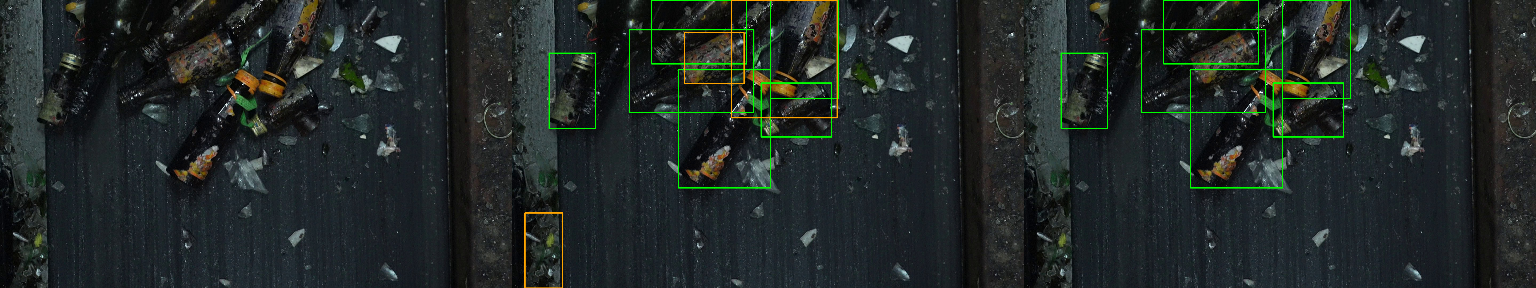


Image: 752620@0_07001_220822_P1_T3__1418.jpg
GT: 5 | OpenCV: 10 | YOLO: 0
왼쪽: 원본 / 가운데: OpenCV / 오른쪽: YOLO


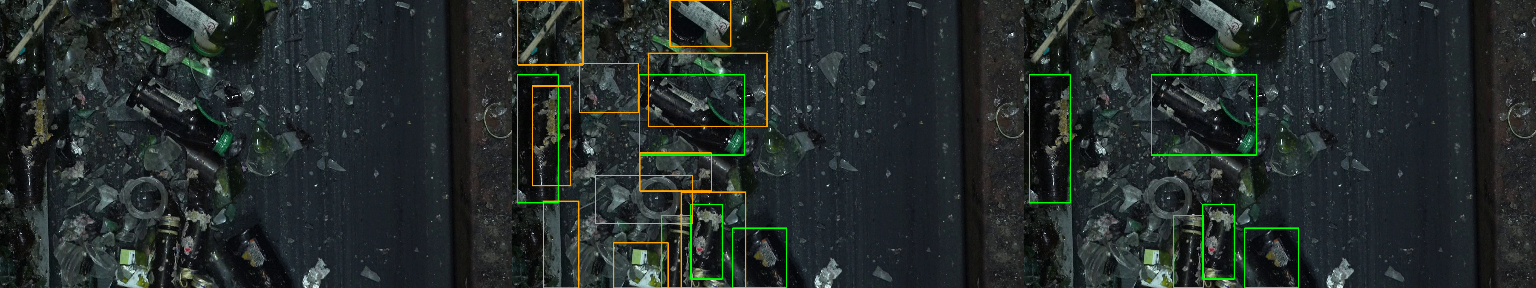


Image: 820824@0_07001_220822_P1_T3__0139.jpg
GT: 5 | OpenCV: 4 | YOLO: 0
왼쪽: 원본 / 가운데: OpenCV / 오른쪽: YOLO


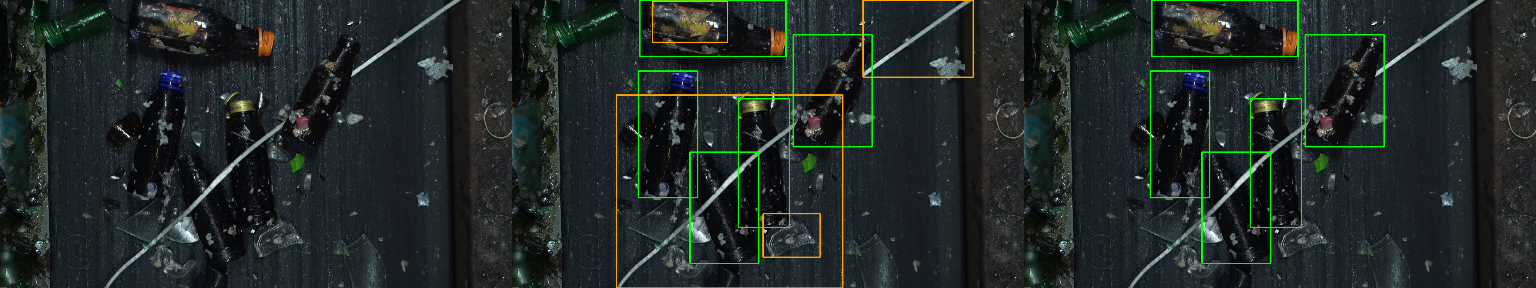


분석 결과 저장 완료


In [8]:

# ── Fallback 후보 수 제한 실험 ──
fallback_trials = []

candidate_limits = [0, 1, 2, 3, 5, 7, 10, 15, 20, 50, 1000]

for max_candidates in candidate_limits:
    use_cv = (
        (yolo["Candidates"] == 0)
        & (cv["Candidates"] > 0)
        & (cv["Candidates"] <= max_candidates)
    )

    hybrid = yolo.copy()
    hybrid.loc[use_cv, columns] = cv.loc[use_cv, columns]
    hybrid["Method"] = "Candidate-limited Fallback"

    score = summary_table(hybrid.reset_index()).iloc[0]

    fallback_trials.append({
        "Max Candidates": max_candidates,
        "Fallback Images": int(use_cv.sum()),
        "Additional TP": int(cv.loc[use_cv, "TP"].sum()),
        "Additional FP": int(cv.loc[use_cv, "FP"].sum()),
        "TP": int(score["TP"]),
        "FP": int(score["FP"]),
        "FN": int(score["FN"]),
        "Precision (%)": score["Precision (%)"],
        "Recall (%)": score["Recall (%)"],
        "F1 (%)": score["F1 (%)"]
    })

df_fallback = pd.DataFrame(fallback_trials)

print("===== FALLBACK THRESHOLD SWEEP =====")
display(
    df_fallback.sort_values(
        ["F1 (%)", "TP", "FP"],
        ascending=[False, False, True]
    ).round(2)
)


# ── 실패 이미지 분류 ──
# GT=0인데 YOLO 후보가 검출된 경우
false_positive_cases = (
    yolo[(yolo["GT"] == 0) & (yolo["FP"] > 0)]
    .sort_values("FP", ascending=False)
)

# GT가 있는데 YOLO 후보 자체가 없는 경우
missed_cases = (
    yolo[
        (yolo["GT"] > 0)
        & (yolo["Candidates"] == 0)
    ].sort_values("GT", ascending=False)
)

print("\n===== FALSE POSITIVE CASES =====")
display(false_positive_cases.head(10))

print("\n===== NO DETECTION CASES =====")
display(missed_cases.head(10))


# ── 대표 실패 이미지 시각화 ──
case_names = list(dict.fromkeys(
    list(false_positive_cases.head(3).index)
    + list(missed_cases.head(3).index)
))

for filename in case_names:
    visualize_comparison(
        VAL_IMAGE_DIR / filename,
        VAL_LABEL_DIR
    )


# ── 분석 결과 저장 ──
analysis.to_csv(
    BASE / "validation_model_analysis.csv",
    encoding="utf-8-sig"
)
df_fallback.to_csv(
    BASE / "validation_fallback_sweep.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\n분석 결과 저장 완료")


---

# CNN 실습

# 데이터준비

In [9]:
from pathlib import Path
from collections import Counter
from tqdm.auto import tqdm

import random
import time
import cv2
import numpy as np

# 랜덤 시드
rng = random.Random(42)

# Crop 저장 경로
CNN_ROOT = Path("/content/brown_bottle_cnn")

# 기존 평가 이미지 목록
all_images = sorted(val_images)

# 촬영 날짜 기준 분할
train_images = [
    p for p in all_images
    if "_220822_" in p.name
]

valid_images = [
    p for p in all_images
    if "_220822_" not in p.name
]

# 데이터 검증
assert len(train_images) + len(valid_images) == 895
assert set(train_images).isdisjoint(valid_images)

print("Training 원본:", len(train_images))
print("Validation 원본:", len(valid_images))
print("CNN 저장 경로:", CNN_ROOT)

Training 원본: 780
Validation 원본: 115
CNN 저장 경로: /content/brown_bottle_cnn


In [ ]:
from tqdm.auto import tqdm
import time

def intersects(a, b):
    ax, ay, aw, ah = a
    bx, by, bw, bh = b

    return (
        ax < bx + bw and
        ax + aw > bx and
        ay < by + bh and
        ay + ah > by
    )

def prepare_crops(files, split):
    counts = Counter()
    start = time.perf_counter()

    progress = tqdm(
        files,
        desc=f"{split.upper()} Crop 생성",
        unit="img",
        dynamic_ncols=True
    )

    for path in progress:
        image, boxes = load_sample(path, VAL_LABEL_DIR)
        height, width = image.shape[:2]

        for i, (x, y, w, h) in enumerate(boxes):
            # Positive
            margin = 0.08 * max(w, h)

            x1 = max(0, int(x - margin))
            y1 = max(0, int(y - margin))
            x2 = min(width, int(x + w + margin))
            y2 = min(height, int(y + h + margin))

            crop = image[y1:y2, x1:x2]

            if crop.size == 0:
                continue

            out = CNN_ROOT / split / "bottle"
            out.mkdir(parents=True, exist_ok=True)

            cv2.imwrite(
                str(out / f"{path.stem}_{i}.jpg"),
                crop
            )
            counts["bottle"] += 1

            # Negative
            patch_w = max(1, min(width, int(round(w))))
            patch_h = max(1, min(height, int(round(h))))

            for _ in range(80):
                nx = rng.randint(0, width - patch_w)
                ny = rng.randint(0, height - patch_h)

                candidate = (nx, ny, patch_w, patch_h)

                if any(intersects(candidate, b) for b in boxes):
                    continue

                bg = image[
                    ny:ny + patch_h,
                    nx:nx + patch_w
                ]

                out = CNN_ROOT / split / "background"
                out.mkdir(parents=True, exist_ok=True)

                cv2.imwrite(
                    str(out / f"{path.stem}_{i}.jpg"),
                    bg
                )
                counts["background"] += 1
                break

        progress.set_postfix(
            bottle=counts["bottle"],
            background=counts["background"]
        )

    elapsed = time.perf_counter() - start

    print(f"\n[{split.upper()} 완료]")
    print(f"처리 이미지: {len(files)}장")
    print(f"Positive: {counts['bottle']}개")
    print(f"Negative: {counts['background']}개")
    print(f"소요 시간: {elapsed:.1f}초")


prepare_crops(train_images, "train")
prepare_crops(valid_images, "val")

TRAIN Crop 생성:   0%|          | 0/780 [00:00<?, ?img/s]

# ImageFolder와 DataLoader 구성

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm

device = torch.device(
    "cuda:0" if torch.cuda.is_available() else "cpu"
)

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

train_set = datasets.ImageFolder(
    CNN_ROOT / "train",
    transform=train_transform
)

valid_set = datasets.ImageFolder(
    CNN_ROOT / "val",
    transform=valid_transform
)

train_loader = DataLoader(
    train_set,
    batch_size=32,
    shuffle=True,
    num_workers=0,  # 기존 2 → 0
    pin_memory=(device.type == "cuda")
)

valid_loader = DataLoader(
        valid_set,
    batch_size=32,
    shuffle=False,
    num_workers=0,  # 기존 2 → 0
    pin_memory=(device.type == "cuda")
)

print("Classes:", train_set.classes)
print("Training crops:", len(train_set))
print("Validation crops:", len(valid_set))
print("Device:", device)

assert train_set.classes == ["background", "bottle"]
assert valid_set.classes == train_set.classes

# ==============================
# DataLoader 전체 배치 로딩 검증
# ==============================

for name, loader in [
    ("Training", train_loader),
    ("Validation", valid_loader)
]:
    total_samples = 0

    progress = tqdm(
        loader,
        desc=f"{name} 데이터 로딩",
        unit="batch",
        dynamic_ncols=True
    )

    for images, labels in progress:
        total_samples += images.size(0)

        progress.set_postfix(
            samples=total_samples,
            shape=str(tuple(images.shape))
        )

    assert total_samples == len(loader.dataset)

    print(f"{name} 로딩 완료: {total_samples}개")

# ==============================
# 입력 Shape 확인
# ==============================

images, labels = next(iter(train_loader))

print("\nInput shape:", images.shape)
print("Label shape:", labels.shape)

# CNN 설계

In [ ]:

class BottleCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # TODO 1:
            # 32채널 -> 64채널
            # Conv -> BatchNorm -> ReLU -> MaxPool
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # TODO 2:
            # 64채널 -> 128채널
            # Conv -> BatchNorm -> ReLU -> MaxPool
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        # TODO 3:
        # self.features와 self.classifier를
        # 순서대로 통과시키고 결과 반환
        x = self.features(x)
        x = self.classifier(x)
        return x


cnn = BottleCNN().to(device)

dummy = torch.randn(4, 3, 128, 128, device=device)

# 추론 모드 (BatchNorm, Dropout 평가 모드)
cnn.eval()

x = dummy

with torch.no_grad():

    layers = (
        list(cnn.features.named_children()) +
        list(cnn.classifier.named_children())
    )

    progress = tqdm(
        layers,
        desc="CNN Forward 검증",
        unit="layer",
        dynamic_ncols=True
    )

    for name, layer in progress:
        x = layer(x)

        progress.set_postfix(
            layer=layer.__class__.__name__,
            shape=str(tuple(x.shape))
        )

        print(
            f"{layer.__class__.__name__:22s}"
            f" → {tuple(x.shape)}"
        )

output = x

print("\n최종 출력 Shape:", output.shape)

assert output.shape == (4, 2)

print("CNN 구조 검증 완료!")

# 학습

In [ ]:
from dataclasses import dataclass
from pathlib import Path

import torch
from torch import nn
import torch.optim as optim
from tqdm.auto import tqdm


@dataclass
class TrainConfig:
    epochs: int = 12
    learning_rate: float = 0.001
    weight_decay: float = 1e-4

    optimizer: str = "AdamW"
    loss_function: str = "CrossEntropyLoss"

    seed: int = 42
    checkpoint_name: str = "bottle_cnn_best.pt"
    save_best: bool = True

    show_progress: bool = True
    log_every: int = 1


config = TrainConfig()

In [ ]:
def create_optimizer(model, config):
    optimizers = {
        "Adam": optim.Adam,
        "AdamW": optim.AdamW,
        "SGD": optim.SGD
    }

    if config.optimizer not in optimizers:
        raise ValueError(
            f"Unsupported optimizer: {config.optimizer}"
        )

    optimizer_cls = optimizers[config.optimizer]

    return optimizer_cls(
        model.parameters(),
        lr=config.learning_rate,
        weight_decay=config.weight_decay
    )


def create_criterion(config):
    criteria = {
        "CrossEntropyLoss": nn.CrossEntropyLoss
    }

    if config.loss_function not in criteria:
        raise ValueError(
            f"Unsupported loss: {config.loss_function}"
        )

    return criteria[config.loss_function]()

In [ ]:
def train_model(
    model,
    train_loader,
    valid_loader,
    device,
    config,
    save_dir
):
    torch.manual_seed(config.seed)

    criterion = create_criterion(config)
    optimizer = create_optimizer(model, config)

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    best_val_loss = float("inf")
    history = []

    epoch_progress = tqdm(
        range(config.epochs),
        desc="CNN Training",
        unit="epoch",
        disable=not config.show_progress
    )

    for epoch in epoch_progress:

        # ==========================
        # Training
        # ==========================
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        train_progress = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{config.epochs} [Train]",
            unit="batch",
            leave=False,
            disable=not config.show_progress
        )

        for inputs, labels in train_progress:
            inputs = inputs.to(
                device,
                non_blocking=True
            )
            labels = labels.to(
                device,
                non_blocking=True
            )

            # ==========================
            # TODO 4: 학습 핵심 5단계
            # ==========================

            # 1. 이전 Gradient 초기화
            optimizer.zero_grad()

            # 2. Forward Propagation
            outputs = model(inputs)

            # 3. Loss 계산
            loss = criterion(outputs, labels)

            # 4. Backward Propagation
            loss.backward()

            # 5. Optimizer로 가중치 업데이트
            optimizer.step()

            # ==========================
            # Training Metrics
            # ==========================
            train_loss += loss.item() * labels.size(0)

            train_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            train_total += labels.size(0)

            train_progress.set_postfix(
                loss=f"{train_loss/train_total:.4f}",
                acc=f"{train_correct/train_total:.2%}"
            )

        # ==========================
        # Validation
        # ==========================
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        val_progress = tqdm(
            valid_loader,
            desc=f"Epoch {epoch+1}/{config.epochs} [Val]",
            unit="batch",
            leave=False,
            disable=not config.show_progress
        )

        with torch.no_grad():
            for inputs, labels in val_progress:
                inputs = inputs.to(
                    device,
                    non_blocking=True
                )
                labels = labels.to(
                    device,
                    non_blocking=True
                )

                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)

                val_correct += (
                    outputs.argmax(dim=1) == labels
                ).sum().item()

                val_total += labels.size(0)

                val_progress.set_postfix(
                    loss=f"{val_loss/val_total:.4f}",
                    acc=f"{val_correct/val_total:.2%}"
                )

        # ==========================
        # Epoch Metrics
        # ==========================
        train_loss /= train_total
        val_loss /= val_total

        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_acc": train_acc,
            "val_acc": val_acc
        })

        # ==========================
        # Best Model Checkpoint
        # ==========================
        if val_loss < best_val_loss:
            best_val_loss = val_loss

            if config.save_best:
                torch.save(
                    model.state_dict(),
                    save_dir / config.checkpoint_name
                )

        # ==========================
        # Epoch Progress
        # ==========================
        epoch_progress.set_postfix(
            train_loss=f"{train_loss:.4f}",
            val_loss=f"{val_loss:.4f}",
            train_acc=f"{train_acc:.2%}",
            val_acc=f"{val_acc:.2%}"
        )

        if (
            not config.show_progress
            and (epoch + 1) % config.log_every == 0
        ):
            print(
                f"Epoch {epoch+1:02d} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Train Acc: {train_acc:.2%} | "
                f"Val Acc: {val_acc:.2%}"
            )

    return history

In [ ]:
torch.manual_seed(config.seed)

cnn = BottleCNN().to(device)

history = train_model(
    model=cnn,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    config=config,
    save_dir=BASE
)

# Loss와 Accuracy 그래프

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df_history = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    df_history["epoch"],
    df_history["train_loss"],
    label="Train"
)
axes[0].plot(
    df_history["epoch"],
    df_history["val_loss"],
    label="Validation"
)
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(
    df_history["epoch"],
    df_history["train_acc"],
    label="Train"
)
axes[1].plot(
    df_history["epoch"],
    df_history["val_acc"],
    label="Validation"
)
axes[1].set_title("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


# 불안정, 과적합발생

In [ ]:
import pandas as pd

df_history = pd.DataFrame(history)

best_epoch = df_history.loc[
    df_history["val_loss"].idxmin()
]

print("===== Best Validation Epoch =====")
print(best_epoch.to_string())

print("\n===== 전체 학습 결과 =====")
print(df_history.round(4).to_string(index=False))

# 학습률 0.0003으로 변경해서 다시학습

In [ ]:
config = TrainConfig(
    epochs=12,
    learning_rate=0.0003,
    weight_decay=1e-4,
    optimizer="AdamW",
    seed=42,
    checkpoint_name="bottle_cnn_lr0003.pt",
    show_progress=True
)

In [ ]:
torch.manual_seed(config.seed)

cnn = BottleCNN().to(device)

history = train_model(
    model=cnn,
    train_loader=train_loader,
    valid_loader=valid_loader,
    device=device,
    config=config,
    save_dir=BASE
)

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df_history = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    df_history["epoch"],
    df_history["train_loss"],
    label="Train"
)
axes[0].plot(
    df_history["epoch"],
    df_history["val_loss"],
    label="Validation"
)
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(
    df_history["epoch"],
    df_history["train_acc"],
    label="Train"
)
axes[1].plot(
    df_history["epoch"],
    df_history["val_acc"],
    label="Validation"
)
axes[1].set_title("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


# 과적합

In [ ]:
import pandas as pd

df_history = pd.DataFrame(history)

best_epoch = df_history.loc[
    df_history["val_loss"].idxmin()
]

print("===== Best Validation Epoch =====")
print(best_epoch.to_string())

print("\n===== 전체 학습 결과 =====")
print(df_history.round(4).to_string(index=False))

# Hyperparameter Optimization(HPO) - Grid Search

In [ ]:
import itertools
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm

# ==========================
# Hyperparameter Search Space
# ==========================

SEARCH_SPACE = {
    "learning_rate": [
        1e-3,
        3e-4,
        1e-4
    ],
    "weight_decay": [
        1e-4,
        1e-3
    ],
    "optimizer": [
        "AdamW"
    ],
    "seed": [
        42
    ]
}

EPOCHS = 12
SAVE_DIR = Path(BASE) / "hpo_checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

keys = list(SEARCH_SPACE)

combinations = [
    dict(zip(keys, values))
    for values in itertools.product(
        *(SEARCH_SPACE[key] for key in keys)
    )
]

print("총 실험 수:", len(combinations))

In [ ]:
results = []
all_histories = {}

for trial_id, params in enumerate(
    tqdm(combinations, desc="Hyperparameter Search"),
    start=1
):
    # 동일 조건에서 재현성 확보
    torch.manual_seed(params["seed"])

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(params["seed"])

    model = BottleCNN().to(device)

    config = TrainConfig(
        epochs=EPOCHS,
        learning_rate=params["learning_rate"],
        weight_decay=params["weight_decay"],
        optimizer=params["optimizer"],
        seed=params["seed"],
        checkpoint_name=f"trial_{trial_id:03d}.pt",
        save_best=True,
        show_progress=False
    )

    history = train_model(
        model=model,
        train_loader=train_loader,
        valid_loader=valid_loader,
        device=device,
        config=config,
        save_dir=SAVE_DIR
    )

    df = pd.DataFrame(history)

    best_idx = df["val_loss"].idxmin()
    best = df.loc[best_idx]

    results.append({
        "trial": trial_id,
        **params,
        "best_epoch": int(best["epoch"]),
        "best_val_loss": float(best["val_loss"]),
        "best_val_acc": float(best["val_acc"]),
        "last_val_loss": float(df.iloc[-1]["val_loss"]),
        "val_loss_std": float(df["val_loss"].std()),
        "checkpoint": str(
            SAVE_DIR / config.checkpoint_name
        )
    })

    all_histories[trial_id] = df.copy()

results_df = (
    pd.DataFrame(results)
    .sort_values("best_val_loss")
    .reset_index(drop=True)
)

display(results_df)

best_result = results_df.iloc[0]

print("===== Best Hyperparameters =====")
print(best_result.to_string())

best_model = BottleCNN().to(device)

state_dict = torch.load(
    best_result["checkpoint"],
    map_location=device,
    weights_only=True
)

best_model.load_state_dict(state_dict)
best_model.eval()

print("\nBest Model Loaded!")

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

best_model.eval()

all_predictions = []
all_labels = []

with torch.inference_mode():
    for inputs, labels in tqdm(
        valid_loader,
        desc="Best Model 평가"
    ):
        inputs = inputs.to(device)

        outputs = best_model(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )
        all_labels.extend(
            labels.numpy()
        )

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=valid_set.classes,
        digits=4,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    cm,
    display_labels=valid_set.classes
).plot(cmap="Blues")

plt.title("Best CNN - Confusion Matrix")
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 검증 이미지 순서를 고정
error_loader = DataLoader(
    valid_set,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

errors = []
best_model.eval()

with torch.inference_mode():
    sample_index = 0

    for inputs, labels in tqdm(
        error_loader,
        desc="오분류 이미지 분석"
    ):
        outputs = best_model(inputs.to(device))
        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = predictions[i].item()

            if true_label != pred_label:
                errors.append({
                    "path": valid_set.samples[sample_index][0],
                    "true": true_label,
                    "pred": pred_label,
                    "confidence": probabilities[i, pred_label].item()
                })

            sample_index += 1

print(f"오분류 이미지: {len(errors)}개")

# FP와 FN 각각 표시
for error_type, title in [
    ((0, 1), "False Positive"),
    ((1, 0), "False Negative")
]:
    selected = [
        e for e in errors
        if (e["true"], e["pred"]) == error_type
    ]

    print(f"\n{title}: {len(selected)}개")

    if not selected:
        continue

    n = min(12, len(selected))
    fig, axes = plt.subplots(
        3, 4,
        figsize=(12, 9)
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, error in zip(axes.flat, selected[:n]):
        image = plt.imread(error["path"])
        ax.imshow(image)
        ax.set_title(
            f"Confidence: {error['confidence']:.1%}",
            fontsize=10
        )

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# YOLO26n 파인튜닝

In [ ]:
!pip -q install -U ultralytics optuna pyyaml

In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
from ultralytics import YOLO
import shutil
import yaml
import cv2
import numpy as np
import optuna
import torch
import pandas as pd

# ===========================
# 실험 환경 설정
# ===========================

YOLO_ROOT = Path("/content/bottle_yolo_dataset")
RUN_ROOT = Path("/content/bottle_yolo_runs")
SAVE_ROOT = Path(BASE) / "bottle_experiments"

RUN_ROOT.mkdir(parents=True, exist_ok=True)
SAVE_ROOT.mkdir(parents=True, exist_ok=True)

SEED = 42
IMGSZ = 640
BATCH_SIZE = 16
IOU_THRESHOLD = 0.5

# 빠른 탐색: 3 trials × 12 epochs
N_TRIALS = 3
TUNE_EPOCHS = 12

# 최고 후보 추가 학습은 처음부터 새로 수행
FINAL_EPOCHS = 30

# Colab GPU
YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("GPU:", YOLO_DEVICE)
print("Train images:", len(train_images))
print("Val images:", len(valid_images))

In [ ]:
def build_yolo_dataset(train_images, valid_images):
    total_boxes = 0

    for split, files in [
        ("train", train_images),
        ("val", valid_images)
    ]:
        img_dir = YOLO_ROOT / "images" / split
        lbl_dir = YOLO_ROOT / "labels" / split

        img_dir.mkdir(parents=True, exist_ok=True)
        lbl_dir.mkdir(parents=True, exist_ok=True)

        for idx, path in enumerate(
            tqdm(files, desc=f"YOLO {split} 준비", unit="img")
        ):
            image, boxes = load_sample(path, VAL_LABEL_DIR)

            H, W = image.shape[:2]
            lines = []

            for x, y, w, h in boxes:
                x1 = max(0.0, float(x))
                y1 = max(0.0, float(y))
                x2 = min(float(W), float(x + w))
                y2 = min(float(H), float(y + h))

                bw, bh = x2 - x1, y2 - y1

                if bw <= 0 or bh <= 0:
                    continue

                cx = ((x1 + x2) / 2) / W
                cy = ((y1 + y2) / 2) / H

                lines.append(
                    f"0 {cx:.6f} {cy:.6f} "
                    f"{bw/W:.6f} {bh/H:.6f}"
                )

            # 인덱스로 파일명 충돌 방지
            name = f"{idx:06d}_{path.stem}"

            shutil.copy2(
                path, img_dir / f"{name}{path.suffix}"
            )

            (lbl_dir / f"{name}.txt").write_text(
                "\n".join(lines), encoding="utf-8"
            )

            total_boxes += len(lines)

    data = {
        "path": str(YOLO_ROOT),
        "train": "images/train",
        "val": "images/val",
        "names": {0: "bottle"}
    }

    yaml_path = YOLO_ROOT / "dataset.yaml"

    with open(yaml_path, "w") as f:
        yaml.safe_dump(data, f, allow_unicode=True)

    print("YOLO dataset:", yaml_path)
    print("Total boxes:", total_boxes)

    return yaml_path


# 기존 데이터셋을 재사용하려면 이 셀 실행 생략
YOLO_YAML = build_yolo_dataset(
    train_images, valid_images
)

## Optuna로 YOLO26n 파인튜닝

In [ ]:
def objective_yolo(trial):
    lr = trial.suggest_float(
        "lr0", 1e-4, 2e-3, log=True
    )
    weight_decay = trial.suggest_float(
        "weight_decay", 1e-5, 1e-3, log=True
    )
    mosaic = trial.suggest_categorical(
        "mosaic", [0.0, 0.5]
    )

    model = YOLO("yolo26n.pt")

    run_name = f"trial_{trial.number:03d}"

    model.train(
        data=str(YOLO_YAML),
        epochs=TUNE_EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        device=YOLO_DEVICE,
        workers=0,
        optimizer="AdamW",
        lr0=lr,
        weight_decay=weight_decay,
        mosaic=mosaic,
        mixup=0.0,
        patience=6,
        seed=SEED,
        project=str(RUN_ROOT),
        name=run_name,
        exist_ok=True,
        verbose=True,
        plots=False
    )

    best_path = (
        RUN_ROOT / run_name / "weights" / "best.pt"
    )

    if not best_path.exists():
        raise FileNotFoundError(best_path)

    metrics = YOLO(str(best_path)).val(
        data=str(YOLO_YAML),
        imgsz=IMGSZ,
        batch=BATCH_SIZE,
        device=YOLO_DEVICE,
        workers=0,
        verbose=False,
        plots=False
    )

    map50 = float(metrics.box.map50)

    trial.set_user_attr("checkpoint", str(best_path))

    return map50


study_yolo = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    study_name="YOLO26n_Finetuning"
)

study_yolo.optimize(
    objective_yolo,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

print("Best Params:", study_yolo.best_params)
print("Best mAP50:", study_yolo.best_value)

## 최적 조합으로 최종 YOLO 학습

In [ ]:
best_params = study_yolo.best_params

final_yolo = YOLO("yolo26n.pt")

final_yolo.train(
    data=str(YOLO_YAML),
    epochs=FINAL_EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH_SIZE,
    device=YOLO_DEVICE,
    workers=0,
    optimizer="AdamW",
    lr0=best_params["lr0"],
    weight_decay=best_params["weight_decay"],
    mosaic=best_params["mosaic"],
    mixup=0.0,
    patience=10,
    seed=SEED,
    project=str(RUN_ROOT),
    name="yolo26n_final",
    exist_ok=True,
    verbose=True,
    plots=True
)

FT_BEST_PATH = (
    RUN_ROOT / "yolo26n_final" / "weights" / "best.pt"
)

assert FT_BEST_PATH.exists()

# Google Drive에 최종 모델 영구 저장
FT_SAVED_PATH = SAVE_ROOT / "yolo26n_finetuned_best.pt"

shutil.copy2(FT_BEST_PATH, FT_SAVED_PATH)

print("Fine-tuned model saved:", FT_SAVED_PATH)

# YOLO26n + BottleCNN

In [ ]:
from PIL import Image
from tqdm.auto import tqdm

# 기존 CNN 최적 모델 불러오기
CNN_BEST_PATH = BASE / "bottle_cnn_lr0003.pt"

# 앞서 Grid Search에서 얻은 최적 checkpoint 우선 사용
if "results_df" in globals():
    CNN_BEST_PATH = Path(
        results_df.iloc[0]["checkpoint"]
    )

cnn_filter = BottleCNN().to(device)

cnn_filter.load_state_dict(
    torch.load(
        CNN_BEST_PATH,
        map_location=device,
        weights_only=True
    )
)

cnn_filter.eval()

# 원본 사전학습 모델 + 파인튜닝 모델
yolo_base = YOLO("yolo26n.pt")
yolo_finetuned = YOLO(str(FT_SAVED_PATH))

# 사전학습 COCO 모델에서 bottle 클래스 찾기
bottle_class_id = next(
    k for k, v in yolo_base.names.items()
    if v == "bottle"
)

print("Pretrained bottle class:", bottle_class_id)
print("Fine-tuned classes:", yolo_finetuned.names)

In [ ]:
def predict_candidates(
    yolo_model,
    files,
    class_id,
    model_name
):
    cache = []

    for path in tqdm(
        files,
        desc=f"{model_name} 후보 추론",
        unit="img"
    ):
        image, gt_boxes = load_sample(
            path, VAL_LABEL_DIR
        )

        result = yolo_model.predict(
            source=image,
            classes=[class_id],
            conf=0.01,
            iou=0.7,
            imgsz=IMGSZ,
            max_det=100,
            device=YOLO_DEVICE,
            verbose=False
        )[0]

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()

        cnn_scores = []

        for x1, y1, x2, y2 in boxes:
            H, W = image.shape[:2]

            margin = 0.08 * max(
                x2 - x1, y2 - y1
            )

            xa = max(0, int(x1 - margin))
            ya = max(0, int(y1 - margin))
            xb = min(W, int(x2 + margin))
            yb = min(H, int(y2 + margin))

            crop = image[ya:yb, xa:xb]

            if crop.size == 0:
                cnn_scores.append(0.0)
                continue

            # OpenCV BGR -> PIL RGB
            crop_rgb = cv2.cvtColor(
                crop, cv2.COLOR_BGR2RGB
            )

            tensor = valid_transform(
                Image.fromarray(crop_rgb)
            ).unsqueeze(0).to(device)

            with torch.inference_mode():
                logits = cnn_filter(tensor)
                probability = torch.softmax(
                    logits, dim=1
                )[0, 1].item()

            cnn_scores.append(probability)

        gt_xyxy = [
            [x, y, x+w, y+h]
            for x, y, w, h in gt_boxes
        ]

        cache.append({
            "image": path.name,
            "gt": np.asarray(
                gt_xyxy, dtype=np.float32
            ).reshape(-1, 4),
            "boxes": boxes,
            "scores": scores,
            "cnn_scores": np.asarray(cnn_scores)
        })

    return cache


base_cache = predict_candidates(
    yolo_base,
    valid_images,
    bottle_class_id,
    "Pretrained YOLO26n"
)

ft_cache = predict_candidates(
    yolo_finetuned,
    valid_images,
    0,
    "Fine-tuned YOLO26n"
)

## F1 계산

In [ ]:
def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    inter = max(0, x2-x1) * max(0, y2-y1)

    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])

    union = area_a + area_b - inter

    return inter / union if union > 0 else 0.0


def evaluate_detection(
    cache,
    yolo_conf=0.25,
    cnn_threshold=None,
    iou_threshold=0.5
):
    TP = FP = FN = 0

    for sample in cache:
        gt = sample["gt"]

        keep = sample["scores"] >= yolo_conf

        if cnn_threshold is not None:
            keep &= (
                sample["cnn_scores"] >= cnn_threshold
            )

        boxes = sample["boxes"][keep]
        scores = sample["scores"][keep]

        # YOLO Confidence 높은 순서로 매칭
        order = np.argsort(-scores)
        matched = set()

        for idx in order:
            pred = boxes[idx]

            best_iou = 0.0
            best_gt = -1

            for j, target in enumerate(gt):
                if j in matched:
                    continue

                iou = box_iou(pred, target)

                if iou > best_iou:
                    best_iou = iou
                    best_gt = j

            if best_iou >= iou_threshold:
                TP += 1
                matched.add(best_gt)
            else:
                FP += 1

        FN += len(gt) - len(matched)

    precision = TP / (TP + FP) if TP + FP else 0
    recall = TP / (TP + FN) if TP + FN else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "Precision": precision * 100,
        "Recall": recall * 100,
        "F1": f1 * 100
    }

## Optuna로 최적화

In [ ]:
def optimize_hybrid(cache, name, n_trials=40):

    def objective(trial):
        yolo_conf = trial.suggest_float(
            "yolo_conf", 0.05, 0.8
        )

        cnn_threshold = trial.suggest_float(
            "cnn_threshold", 0.05, 0.95
        )

        metrics = evaluate_detection(
            cache,
            yolo_conf=yolo_conf,
            cnn_threshold=cnn_threshold,
            iou_threshold=IOU_THRESHOLD
        )

        return metrics["F1"]

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        ),
        study_name=name
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        show_progress_bar=True
    )

    print(f"\n[{name}]")
    print("Best Params:", study.best_params)
    print("Best F1:", study.best_value)

    return study


# 기존 YOLO + CNN
study_base_hybrid = optimize_hybrid(
    base_cache,
    "YOLO26n_BottleCNN"
)

# 파인튜닝 YOLO + CNN
study_ft_hybrid = optimize_hybrid(
    ft_cache,
    "FineTuned_YOLO26n_BottleCNN"
)

# 최종 비교

In [ ]:
def optimize_yolo_conf(cache, n_trials=40):

    def objective(trial):
        conf = trial.suggest_float(
            "yolo_conf", 0.05, 0.8
        )

        return evaluate_detection(
            cache,
            yolo_conf=conf,
            iou_threshold=IOU_THRESHOLD
        )["F1"]

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(
            seed=SEED
        )
    )

    study.optimize(
        objective,
        n_trials=n_trials,
        show_progress_bar=True
    )

    return study.best_params["yolo_conf"]


base_conf = optimize_yolo_conf(base_cache)
ft_conf = optimize_yolo_conf(ft_cache)

comparison = []

experiments = [
    (
        "Pretrained YOLO26n",
        base_cache,
        base_conf,
        None
    ),
    (
        "Fine-tuned YOLO26n",
        ft_cache,
        ft_conf,
        None
    ),
    (
        "YOLO26n + BottleCNN",
        base_cache,
        study_base_hybrid.best_params["yolo_conf"],
        study_base_hybrid.best_params["cnn_threshold"]
    ),
    (
        "Fine-tuned YOLO26n + BottleCNN",
        ft_cache,
        study_ft_hybrid.best_params["yolo_conf"],
        study_ft_hybrid.best_params["cnn_threshold"]
    )
]

for name, cache, conf, cnn_thresh in tqdm(
    experiments,
    desc="최종 성능 비교",
    unit="model"
):
    metrics = evaluate_detection(
        cache,
        yolo_conf=conf,
        cnn_threshold=cnn_thresh,
        iou_threshold=IOU_THRESHOLD
    )

    comparison.append({
        "Method": name,
        "YOLO Conf": conf,
        "CNN Threshold": cnn_thresh,
        **metrics
    })

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df.sort_values(
        "F1", ascending=False
    )
)

comparison_df.to_csv(
    SAVE_ROOT / "yolo_cnn_comparison.csv",
    index=False
)

# Final Test

In [ ]:
from pathlib import Path

TEST_ROOT = BASE / "test_dataset"

TEST_IMAGE_DIR = TEST_ROOT / "images"
TEST_LABEL_DIR = TEST_ROOT / "labels"

test_images = sorted([
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

test_labels = sorted(
    TEST_LABEL_DIR.glob("*.json")
)

print("Test 이미지:", len(test_images))
print("Test JSON:", len(test_labels))

assert len(test_images) == 105
assert len(test_labels) == 105

image_names = {p.stem for p in test_images}
label_names = {p.stem for p in test_labels}

assert image_names == label_names, (
    f"이미지만 있는 파일: {image_names - label_names}\n"
    f"JSON만 있는 파일: {label_names - image_names}"
)

print("Test 데이터 무결성 검증 완료!")

In [ ]:
FINAL_YOLO_CONF = 0.217505

FINAL_HYBRID_CONF = 0.219687
FINAL_CNN_THRESHOLD = 0.051202

FINAL_IOU = 0.5

In [ ]:
from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd
import numpy as np
import torch
import cv2

TEST_ROOT = BASE / "test_dataset"
TEST_IMAGE_DIR = TEST_ROOT / "images"
TEST_LABEL_DIR = TEST_ROOT / "labels"

TEST_COUNT = 105
IOU_THRESHOLD = 0.5

test_images = sorted(
    p for p in TEST_IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
)

test_labels = sorted(TEST_LABEL_DIR.glob("*.json"))

assert len(test_images) == TEST_COUNT
assert len(test_labels) == TEST_COUNT

image_names = {p.stem for p in test_images}
label_names = {p.stem for p in test_labels}

assert image_names == label_names, (
    f"이미지만 존재: {image_names - label_names}\n"
    f"JSON만 존재: {label_names - image_names}"
)

# 기존 데이터와 파일명 중복 검사
dev_names = {
    p.name for p in list(train_images) + list(valid_images)
}

duplicates = {
    p.name for p in test_images
} & dev_names

assert not duplicates, (
    f"기존 데이터와 파일명 중복: {duplicates}"
)

# 실제 JSON 파싱 및 이미지 로딩 검사
total_gt = 0

for path in tqdm(
    test_images,
    desc="TEST 무결성 검사",
    unit="img"
):
    image, boxes = load_sample(path, TEST_LABEL_DIR)

    assert image is not None, path

    total_gt += len(boxes)

print("TEST 이미지:", len(test_images))
print("TEST JSON:", len(test_labels))
print("TEST GT:", total_gt)
print("무결성 검사 완료!")

In [ ]:
from ultralytics import YOLO
from torchvision import transforms
from PIL import Image

YOLO_DEVICE = 0 if torch.cuda.is_available() else "cpu"

# 기존 학습 완료 모델 사용
yolo_base = YOLO("yolo26n.pt")

yolo_finetuned = YOLO(
    str(BASE / "bottle_experiments" /
        "yolo26n_finetuned_best.pt")
)

# 기존 best_model이 메모리에 남아 있다는 전제
cnn_filter = best_model.to(device)
cnn_filter.eval()

bottle_class_id = next(
    k for k, name in yolo_base.names.items()
    if name == "bottle"
)

# Validation에서 확정한 설정
CONFIGS = {
    "Pretrained YOLO26n": {
        "yolo_conf": 0.102600,
        "cnn_threshold": None
    },
    "YOLO26n + BottleCNN": {
        "yolo_conf": 0.061591,
        "cnn_threshold": 0.557456
    },
    "Fine-tuned YOLO26n": {
        "yolo_conf": 0.217505,
        "cnn_threshold": None
    },
    "Fine-tuned YOLO26n + BottleCNN": {
        "yolo_conf": 0.219687,
        "cnn_threshold": 0.051202
    }
}

assert len(test_images) == 105

print("모델 로딩 완료!")

In [ ]:
def predict_test_candidates(
    yolo_model,
    files,
    class_id,
    model_name,
    label_dir=TEST_LABEL_DIR
):
    cache = []

    for path in tqdm(
        files,
        desc=f"{model_name} TEST 추론",
        unit="img",
        dynamic_ncols=True
    ):
        image, gt_boxes = load_sample(
            path, label_dir
        )

        result = yolo_model.predict(
            source=image,
            classes=[class_id],
            conf=0.01,
            iou=0.7,
            imgsz=640,
            max_det=100,
            device=YOLO_DEVICE,
            verbose=False
        )[0]

        boxes = result.boxes.xyxy.cpu().numpy()
        scores = result.boxes.conf.cpu().numpy()

        cnn_scores = []
        H, W = image.shape[:2]

        for x1, y1, x2, y2 in boxes:
            margin = 0.08 * max(
                x2 - x1, y2 - y1
            )

            xa = max(0, int(x1 - margin))
            ya = max(0, int(y1 - margin))
            xb = min(W, int(x2 + margin))
            yb = min(H, int(y2 + margin))

            crop = image[ya:yb, xa:xb]

            if crop.size == 0:
                cnn_scores.append(0.0)
                continue

            crop_rgb = cv2.cvtColor(
                crop, cv2.COLOR_BGR2RGB
            )

            tensor = valid_transform(
                Image.fromarray(crop_rgb)
            ).unsqueeze(0).to(device)

            with torch.inference_mode():
                logits = cnn_filter(tensor)
                score = torch.softmax(
                    logits, dim=1
                )[0, 1].item()

            cnn_scores.append(score)

        gt_xyxy = [
            [x, y, x + w, y + h]
            for x, y, w, h in gt_boxes
        ]

        cache.append({
            "image": path.name,
            "gt": np.asarray(
                gt_xyxy,
                dtype=np.float32
            ).reshape(-1, 4),
            "boxes": boxes,
            "scores": scores,
            "cnn_scores": np.asarray(cnn_scores)
        })

    return cache

In [ ]:
base_test_cache = predict_test_candidates(
    yolo_model=yolo_base,
    files=test_images,
    class_id=bottle_class_id,
    model_name="Pretrained YOLO26n"
)

ft_test_cache = predict_test_candidates(
    yolo_model=yolo_finetuned,
    files=test_images,
    class_id=0,
    model_name="Fine-tuned YOLO26n"
)

assert len(base_test_cache) == 105
assert len(ft_test_cache) == 105

print("TEST 추론 및 CNN 후보 평가 완료!")

In [ ]:
test_experiments = [
    ("Pretrained YOLO26n", base_test_cache),
    ("YOLO26n + BottleCNN", base_test_cache),
    ("Fine-tuned YOLO26n", ft_test_cache),
    ("Fine-tuned YOLO26n + BottleCNN", ft_test_cache)
]

test_results = []

for name, cache in tqdm(
    test_experiments,
    desc="최종 TEST 성능 평가",
    unit="model"
):
    cfg = CONFIGS[name]

    metrics = evaluate_detection(
        cache,
        yolo_conf=cfg["yolo_conf"],
        cnn_threshold=cfg["cnn_threshold"],
        iou_threshold=IOU_THRESHOLD
    )

    test_results.append({
        "Method": name,
        "Images": len(test_images),
        "GT": total_gt,
        "YOLO Conf": cfg["yolo_conf"],
        "CNN Threshold": cfg["cnn_threshold"],
        **metrics
    })

test_df = pd.DataFrame(test_results)

display(
    test_df.sort_values(
        "F1", ascending=False
    ).round(3)
)

TEST_RESULT_PATH = (
    BASE / "bottle_experiments" /
    "final_test_results.csv"
)

test_df.to_csv(
    TEST_RESULT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("최종 TEST 결과 저장:", TEST_RESULT_PATH)

# Fine-tuned YOLO26n 단독 모델을 최종 후보로 채택

## 기존 YOLO26n 에서 Optuna로 최적의 설정을 찾고, 그 설정으로 Fine-tuning한 모델

---

In [ ]:

from collections import Counter
from pathlib import Path
import json
import pandas as pd

# Test 데이터 제외
label_dirs = [
    Path(globals()[name])
    for name in ("TRAIN_LABEL_DIR", "VAL_LABEL_DIR")
    if name in globals()
]

if not label_dirs:
    raise ValueError("TRAIN_LABEL_DIR 또는 VAL_LABEL_DIR가 필요합니다.")

object_counts = Counter()
image_counts = Counter()

for label_dir in label_dirs:
    for path in label_dir.glob("*.json"):
        with open(path, encoding="utf-8-sig") as f:
            data = json.load(f)

        present_classes = set()

        for obj in data.get("ANNOTATION_INFO", []):
            if not obj.get("POINTS"):
                continue

            key = (
                obj.get("CLASS"),
                obj.get("DETAILS")
            )

            object_counts[key] += 1
            present_classes.add(key)

        for key in present_classes:
            image_counts[key] += 1

df_classes = pd.DataFrame([
    {
        "CLASS": key[0],
        "DETAILS": key[1],
        "Objects": count,
        "Images": image_counts[key]
    }
    for key, count in object_counts.items()
]).sort_values("Objects", ascending=False)

display(df_classes)
print("총 객체:", sum(object_counts.values()))
